# FUNCIONES DE PERDIDA Y DESCENSO DE GRADIENTE


## FUNCIONES DE PERDIDA

Entrenar un modelo significa establecer sus parámetros de manera que el modelo se ajuste lo mejor posible al conjunto de entrenamiento, es decir, los parámetros del modelo que minimizan la función de pérdida sobre el conjunto de entrenamiento. La función de pérdida, también denominada función de error, es un componente crucial en el machine learning que cuantifica la diferencia entre los resultados previstos de un algoritmo de machine learning y los valores objetivo reales.

La función de pérdida es lo que nos proporciona la medida de rendimiento y precisión del modelo, es decir lo bien o mal que se ajusta el modelo a los datos de entrenamiento.  La función de pérdida actúa como guía para el proceso de aprendizaje dentro de un modelo o algoritmo de machine learning.

El papel de la función de pérdida es crucial en el entrenamiento de los modelos de machine learning e incluye lo siguiente:

- *Medición del rendimiento:* Las funciones de pérdida ofrecen una métrica clara para evaluar el rendimiento de un modelo, cuantificando la diferencia entre las predicciones y los resultados reales.

- *Dirección para la mejora:* Las funciones de pérdida guían la mejora del modelo dirigiendo al algoritmo para que ajuste los parámetros (pesos) de forma iterativa para reducir la pérdida y mejorar las predicciones.

- *Equilibrar el sesgo y la varianza:* Las funciones de pérdida eficaces ayudan a equilibrar el sesgo del modelo (simplificación excesiva) y la varianza (ajuste excesivo), algo esencial para la generalización del modelo a nuevos datos.

- *Influir en el comportamiento del modelo:* Determinadas funciones de pérdida pueden afectar al comportamiento del modelo, como ser más robusto frente a los datos atípicos o dar prioridad a tipos concretos de errores.


La búsqueda de los valores de los parámetros que minimizan la función de pérdida podríamos hacerla mediante *fuerza bruta*, es decir, generando valores aleatorios de los parámetros millones de veces y eligiendo aquellos que nos dan el valor más bajo para la función objetivo. Sin embargo esta metodología es muy ineficiente desde el punto de vista temporal porque nos llevaría demasiado tiempo. Para lograr una búsqueda de valores de parámetros más eficiente existen diferentes técnicas:

- La ecuación normal (inversión de matrices)

- La descomposición matricial

- El descenso de gradiente

# FUNCIONES DE PERDIDA PARA LA REGRESION

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FUNCIONES DE PÉRDIDA PARA REGRESIÓN
# ============================================================
# Todas reciben:
#   y_true: array con los valores reales
#   y_pred: array con los valores predichos por el modelo
# Y devuelven un único número (escalar) con el valor de la pérdida.

def mse(y_true, y_pred):
    """
    Mean Squared Error (Error Cuadrático Medio)
    Eleva cada error al cuadrado y promedia. 
    Penaliza fuertemente los errores grandes.
    """
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    """
    Root Mean Squared Error (Raíz del Error Cuadrático Medio)
    Es simplemente la raíz cuadrada del MSE.
    Tiene las mismas unidades que la variable original.
    """
    return np.sqrt(mse(y_true, y_pred))


def mae(y_true, y_pred):
    """
    Mean Absolute Error (Error Absoluto Medio)
    Promedia el valor absoluto de los errores.
    Más robusta a outliers que MSE.
    """
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs(y_true - y_pred))


def huber_loss(y_true, y_pred, delta=1.0):
    """
    Huber Loss
    Combina MSE (para errores pequeños) y MAE (para errores grandes).
    'delta' es el umbral que decide dónde cambia de una fórmula a otra.
    """
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    error = y_true - y_pred
    is_small_error = np.abs(error) <= delta

    squared_loss = 0.5 * error ** 2                          # rama cuadrática
    linear_loss = delta * (np.abs(error) - 0.5 * delta)      # rama lineal

    return np.mean(np.where(is_small_error, squared_loss, linear_loss))


# EJEMPLO DE USO


y_true = np.array([3.0, -0.5, 2.0, 7.0, 4.5])
y_pred = np.array([2.5, 0.0, 2.0, 8.0, 9.0])   # el último valor es un outlier grande

print(f"MSE   : {mse(y_true, y_pred):.4f}")
print(f"RMSE  : {rmse(y_true, y_pred):.4f}")
print(f"MAE   : {mae(y_true, y_pred):.4f}")
print(f"Huber : {huber_loss(y_true, y_pred, delta=1.0):.4f}")

# Fíjate cómo MSE y RMSE se disparan más que MAE por culpa del outlier (9.0 vs 4.5)

MSE   : 4.3500
RMSE  : 2.0857
MAE   : 1.3000
Huber : 0.9500


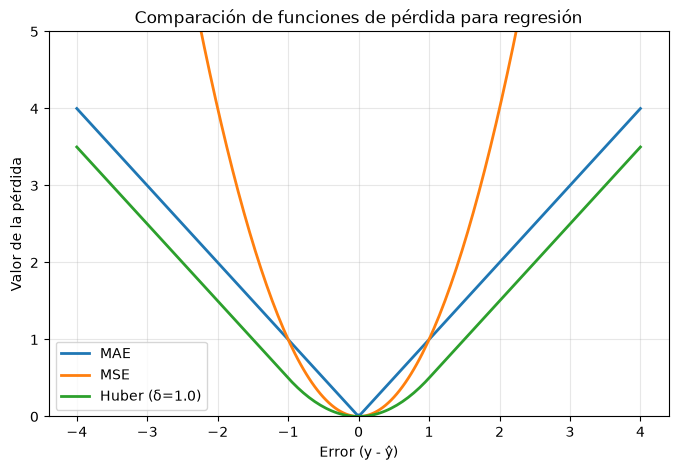

In [23]:
# COMPARACIÓN VISUAL: PÉRDIDA vs ERROR (y - ŷ)

# Este gráfico reproduce la comparación de formas de funciones de error:
# MAE = V, MSE = parábola,Huber = combinación de ambas.

errors = np.linspace(-4, 4, 200)

mae_vals = np.abs(errors)
mse_vals = errors ** 2
delta = 1.0
huber_vals = np.where(
    np.abs(errors) <= delta,
    0.5 * errors ** 2,
    delta * (np.abs(errors) - 0.5 * delta)
)

plt.figure(figsize=(8, 5))
plt.plot(errors, mae_vals, label="MAE", linewidth=2)
plt.plot(errors, mse_vals, label="MSE", linewidth=2)
plt.plot(errors, huber_vals, label=f"Huber (δ={delta})", linewidth=2)

plt.xlabel("Error (y - ŷ)")
plt.ylabel("Valor de la pérdida")
plt.title("Comparación de funciones de pérdida para regresión")
plt.ylim(0, 5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Descenso de gradiente

Los métodos vistos hasta ahora (la ecuación normal y la descomposición matricial) escalan linealmente con el número de instancias, pero su coste crece de forma cuadrática (o peor) con el número de características. En los casos en los que hay un número elevado de características o demasiadas instancias de entrenamiento para caber en la memoria necesitamos de un método más avanzado denominado descenso de gradiente.

### Regresión lineal con descenso de gradiente

Intersección con eje Y (b): 18.29
Pendiente (m): 1.47
RSS:  370.38
MSE:  7.41
RMSE: 2.72


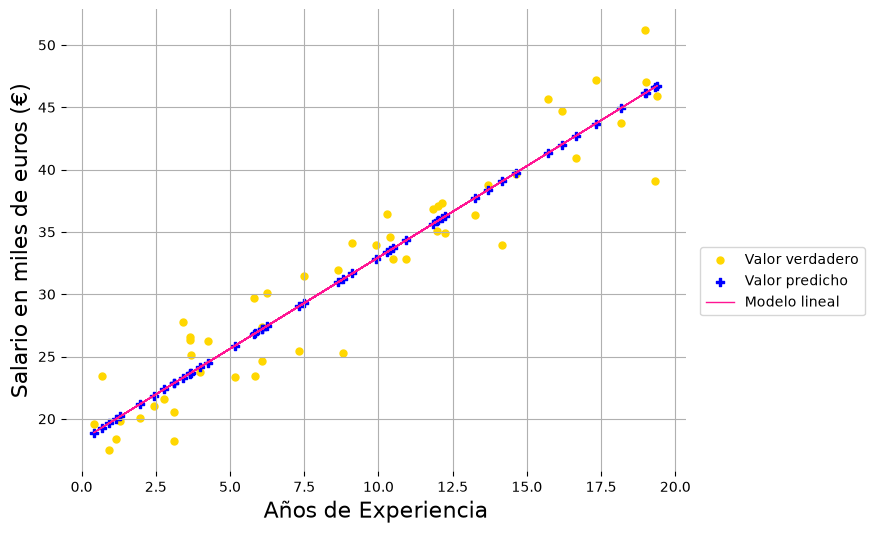

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym
from sklearn.linear_model import LinearRegression


# Generamos un conjunto de datos aleatorios
np.random.seed(42)
m = 50 # número de instancias

# Variable independiente: entre 0 y 20 años de experiencia
experiencia = 20 * np.random.rand(m, 1)

# Variable objetivo: salario base de 18 mil € + 1,5 mil € por año + ruido
salario = 18 + 1.5 * experiencia + 3 * np.random.randn(m, 1)

# Modelo lineal creado con el método de mínimos cuadrados
modelo = LinearRegression().fit(experiencia, salario)

# Visualización de datos y modelo
print("Intersección con eje Y (b): %0.2f" % modelo.intercept_[0])
print("Pendiente (m): %0.2f" % modelo.coef_[0][0])
residuos = salario - modelo.predict(experiencia)

rss = (residuos**2).sum()    # suma de cuadrados de los residuos
mse_val = (residuos**2).mean()   # error cuadrático medio = RSS / m
rmse_val = np.sqrt(mse_val)      # raíz del MSE, en las mismas unidades que el salario

print("RSS:  %0.2f" % rss)
print("MSE:  %0.2f" % mse_val)
print("RMSE: %0.2f" % rmse_val)

plt.figure(figsize=(8, 6))

plt.scatter(experiencia, salario, color="gold", s=25,
            marker="o", label="Valor verdadero")

plt.scatter(experiencia, modelo.predict(experiencia),
            color="blue", s=35, marker="P", label="Valor predicho") 

plt.plot(experiencia, modelo.predict(experiencia),
         linewidth=1, color="deeppink", label="Modelo lineal") 


plt.ylabel("Salario en miles de euros (€)", size=16)
plt.xlabel("Años de Experiencia", size=16)
plt.legend(bbox_to_anchor=(1.3, 0.5))
plt.grid()
plt.box(False)
plt.show()


Este modelo ha estimado sus parámetros minimizando la suma de los cuadrados de los residuos (RSS) utilizando la descomposición de matrices.

### Diferentes modelos con diferentes pendientes

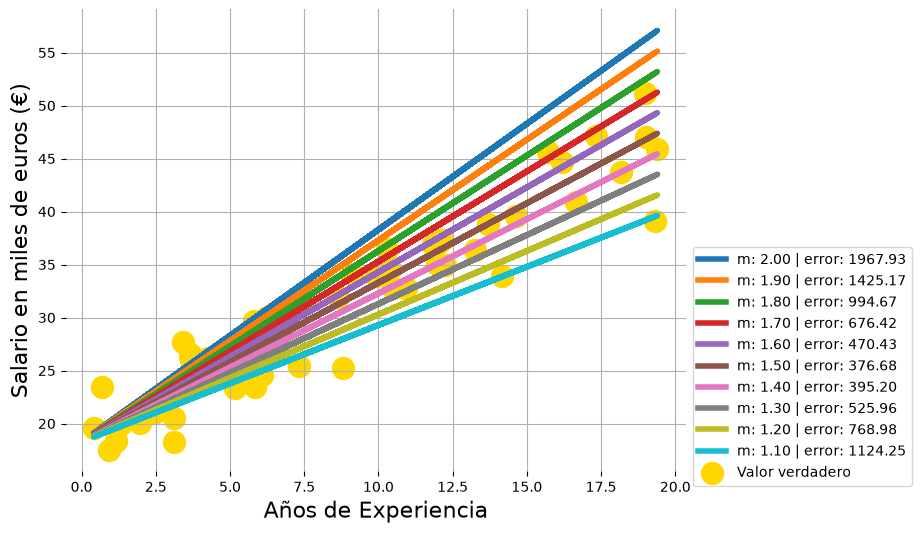

In [25]:
# Creación de múltiples pendientes para exploración
pendientes = np.arange(2.0, 1.0, -0.1)
intercepto = 18.29

# Vector para almacenar el error de los diferentes modelos
errores = np.array([])

# Visualización de modelos

plt.figure(figsize=(8, 6))

for pendiente in pendientes: 
    # Error del modelo (suma de cuadrados de los residuos)
    error = ((intercepto + pendiente*experiencia - salario)**2).sum()

    # Visualización de un modelo para una pendiente dada
    plt.plot(experiencia, intercepto + pendiente*experiencia, linewidth=4, 
             label="m: %0.2f | error: %0.2f" %
            (pendiente, error)) 
    
    errores = np.append(errores, error)

plt.scatter(experiencia, salario, color="gold", s=250,
            marker="o", label="Valor verdadero")

plt.ylabel("Salario en miles de euros (€)", size=16)
plt.xlabel("Años de Experiencia", size=16)
plt.legend(bbox_to_anchor=(1, 0.5))
plt.grid()
plt.box(False)
plt.show()

### Visualización de los errores/residuos al cuadrado

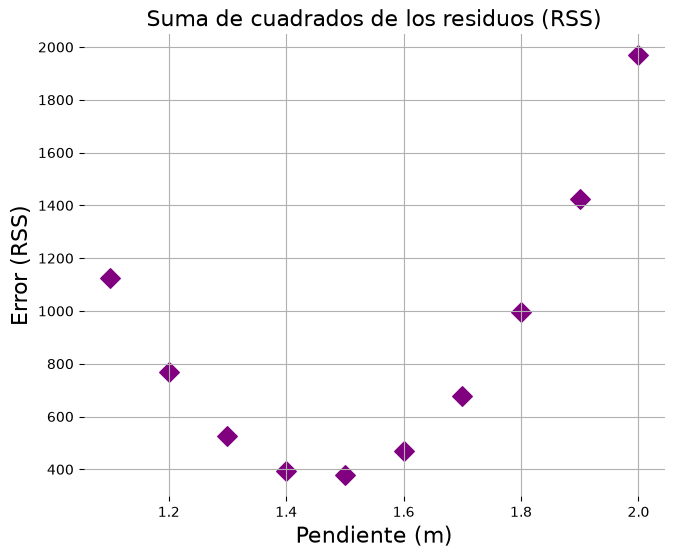

In [26]:
plt.figure(figsize=(7.5, 6))
plt.title("Suma de cuadrados de los residuos (RSS)", size=16)
plt.ylabel("Error (RSS)", size=16)
plt.xlabel("Pendiente (m)", size=16)
plt.scatter(pendientes, errores, color="purple", marker="D", s=99) 
plt.grid()
plt.box(False)
plt.show()

Representación del error frente a los diferentes valores de pendiente

### Función de Error a ser Minimizada
#### Suma de los cuadrados de los residuos (RSS)

$$\text{RSS}(y, \hat{y}) = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$ y_i = \text{salario}_i $$

$$ \hat{y}_i = b + m\cdot\text{experiencia}_i $$

Donde $y$ son los valores verdaderos, $\hat{y}$ son los valores predichos, $b$ es el intercepto (fijo) y $n$ es el tamaño de la muestra.

#### Derivada del error respecto a la pendiente $m$

Sustituyendo el modelo en el RSS:

$$\text{RSS}(m) = \sum_{i=1}^{n} \left(y_i - (b + m\cdot x_i)\right)^2$$

donde $x_i = \text{experiencia}_i$. Aplicando la regla de la cadena a cada término:

$$\frac{d\,\text{RSS}}{dm} = \sum_{i=1}^{n} 2\left(y_i - b - m\cdot x_i\right)\cdot(-x_i) = -2\sum_{i=1}^{n} x_i\left(y_i - b - m\cdot x_i\right)$$

Esta derivada es una función lineal de $m$. Igualándola a cero se obtiene la pendiente que minimiza el error:

$$\frac{d\,\text{RSS}}{dm} = 0 \quad\Rightarrow\quad m^* = \frac{\sum_{i=1}^{n} x_i\,(y_i - b)}{\sum_{i=1}^{n} x_i^{2}}$$


In [27]:
# Convertimos en listas experiencia y salario

experiencia = list(experiencia.ravel())
salario = list(salario.ravel())

pares_de_valores_experiencia_salario = list(zip(experiencia, salario))

In [28]:
# Medimos la pendiente 


m = sym.Symbol("m") # generamos un simbolo de la biblioteca sympy; generamos una variable sobre la que haremos una operación

# Generamos la función de error
error = []
for i in range(len(pares_de_valores_experiencia_salario)):
    x = pares_de_valores_experiencia_salario[i][0]
    y = pares_de_valores_experiencia_salario[i][1]
    error.append((y - (m*x+intercepto))**2)
error = sum(error)

# Derivada de la función de error con respecto a m
derivada = sym.diff(error, m) # derivada = -2 · Σ xᵢ · (yᵢ - m·xᵢ - b)

print("Derivada del error (RSS) respecto a m:", derivada)

for pendiente in pendientes:
    print("Evaluación en m = %0.2f: %0.2f" % (pendiente, derivada.evalf(subs={m: pendiente})))

Derivada del error (RSS) respecto a m: 11225.3024896211*m - 16461.7970936062
Evaluación en m = 2.00: 5988.81
Evaluación en m = 1.90: 4866.28
Evaluación en m = 1.80: 3743.75
Evaluación en m = 1.70: 2621.22
Evaluación en m = 1.60: 1498.69
Evaluación en m = 1.50: 376.16
Evaluación en m = 1.40: -746.37
Evaluación en m = 1.30: -1868.90
Evaluación en m = 1.20: -2991.43
Evaluación en m = 1.10: -4113.96


El primer término es la derivada del error, el segundo es la pendiente de la función respecto a diferentes valores de m

## Visualizamos la derivada del error en función de la pendiente

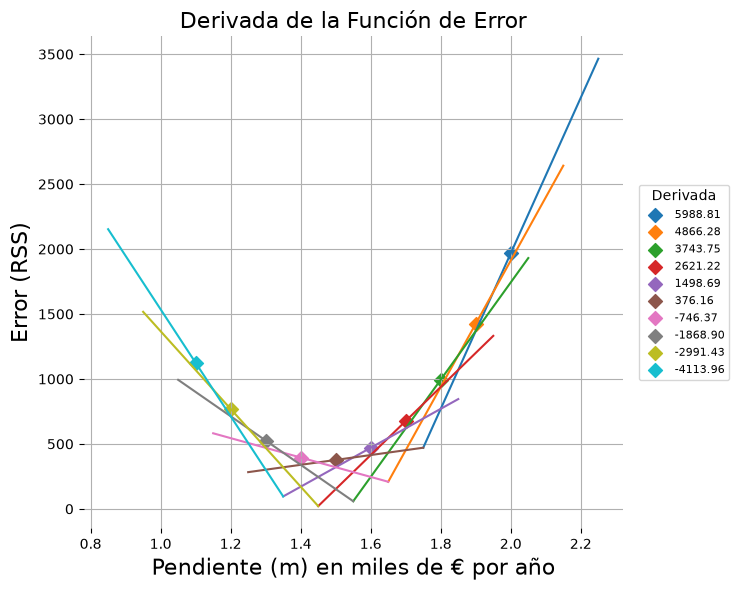

In [29]:
# Datos como arrays (funciona aunque experiencia/salario sean listas)
x_d = np.array(experiencia).ravel()
y_d = np.array(salario).ravel()

# Recalculamos los errores para estas pendientes (mismo modelo que la derivada)
errores = np.array([((y_d - (intercepto + p*x_d))**2).sum() for p in pendientes])

plt.figure(figsize=(7.5, 6))

for i in range(0, len(errores), 1):
    # Derivada del error en esta pendiente
    derivada_i = float(derivada.evalf(subs={m: pendientes[i]}))

    # Error de un modelo dado
    plt.scatter(pendientes[i], errores[i],
                label="%0.2f" % derivada_i,
                marker="D", s=50)

    # Recta tangente: y = error_i + derivada_i * (x - m_i)
    xs = np.array([pendientes[i] - 0.25, pendientes[i] + 0.25])
    plt.plot(xs, errores[i] + derivada_i * (xs - pendientes[i]))

plt.title("Derivada de la Función de Error", size=16)
plt.ylabel("Error (RSS)", size=16)
plt.xlabel("Pendiente (m) en miles de € por año", size=16)
plt.legend(title="Derivada", bbox_to_anchor=(1.02, 0.5), loc="center left", fontsize=8)
plt.grid()
plt.box(False)
plt.tight_layout()
plt.show()

## Generalizando para 2 o más parámetros (m y b)

Incluiremos la estimación del intercepto



### Error Cuadrático Medio (MSE) y sus Derivadas Parciales

#### Función de Error (MSE)

Para un modelo de regresión lineal simple $\hat{y}_i = mx_i + b$, el error cuadrático medio se define como:

$$
MSE(m, b) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = \frac{1}{n} \sum_{i=1}^{n} \big(y_i - (mx_i + b)\big)^2
$$

donde:
- $n$ = número de observaciones
- $y_i$ = valor real
- $\hat{y}_i = mx_i + b$ = valor predicho
- $m$ = pendiente
- $b$ = intercepto

#### Derivada Parcial respecto a la pendiente ($m$)

$$
\frac{\partial MSE}{\partial m} = \frac{-2}{n} \sum_{i=1}^{n} x_i \big(y_i - (mx_i + b)\big)
$$

#### Derivada Parcial respecto al intercepto ($b$)

$$
\frac{\partial MSE}{\partial b} = \frac{-2}{n} \sum_{i=1}^{n} \big(y_i - (mx_i + b)\big)
$$

#### Actualización de parámetros (descenso de gradiente)

$$
m := m - \alpha \frac{\partial MSE}{\partial m}, \qquad b := b - \alpha \frac{\partial MSE}{\partial b}
$$

donde $\alpha$ es la tasa de aprendizaje.

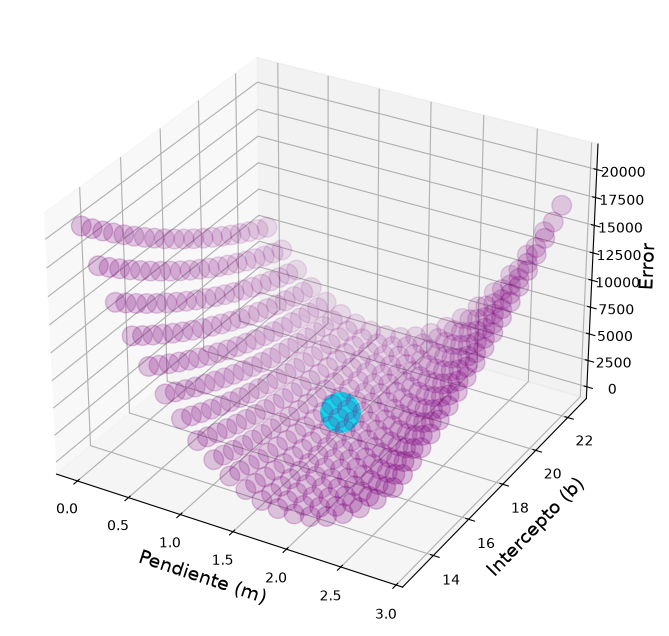

In [30]:
x_d = np.array(experiencia).ravel()
y_d = np.array(salario).ravel()

# Construcción de la función de error
def error_RSS(m, b):
    return ((y_d - (m*x_d + b))**2).sum()

# Generación de rejilla (pendientes, interceptos, errores)
puntos = np.zeros(shape=(400,3)) # generamos una tabla vacía con 400 filas y tres columnas (pendientes, interceptos, errores)
i = 0
for m_val in np.linspace(0, 3, 20, endpoint=False):        # probamos 20 pendientes entre 0 y 3 (cada 0.15)
    for b_val in np.linspace(13, 23, 20, endpoint=False):  # para cada pendiente, probamos interceptos entre 13 y 23 (cada 0.5)
        puntos[i][0] = m_val
        puntos[i][1] = b_val
        puntos[i][2] = error_RSS(m_val, b_val)
        i += 1

# Mínimo global 
m_opt, b_opt = np.polyfit(x_d, y_d, 1) # ajusta una recta por mínimos cuadrados (similar a LinearRegression; descomposición en valores singulares) y devuelve pendiente (m) e intercepto (b)
e_opt = error_RSS(m_opt, b_opt) # El error de la recta ajustada (el mínimo)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")

# Mínimo global (punto azul)
ax.scatter(m_opt, b_opt, e_opt,
           marker="o", c="cyan", s=800)

# Todos los otros puntos
ax.scatter(puntos.T[0], puntos.T[1], puntos.T[2], # Se usa transposición para que cada fila de la matriz generada corresponda a una variable
           marker="o", c="purple", s=200, alpha=0.5)

ax.set_xlabel('Pendiente (m)', size=14)
ax.set_ylabel('Intercepto (b)', size=14)
ax.set_zlabel('Error', size=14)
#ax.view_init(0, -30)
plt.show()

## Derivadas parciales de la función de error con Sympy



In [ ]:

x_d = np.array(experiencia).ravel()
y_d = np.array(salario).ravel()

m, b = sym.symbols("m b")

# Construcción de la función de error
def error_RSS(m, b):
    return sum((float(y) - (m*float(x) + b))**2 for x, y in zip(x_d, y_d))

error = error_RSS(m, b)

derivada_error_m = sym.diff(error, m)
derivada_error_b = sym.diff(error, b)

print(f"Función de error: {sym.expand(error)}") # sympy.expand transforma expresiones matemáticas complejas (como productos de polinomios, potencias, funciones trigonométricas o exponenciales) en una forma extendida
print(f"Derivada parcial de la pendiente: {derivada_error_m}")
print(f"Derivada parcial del intercepto: {derivada_error_b}")

Función de error: 50*b**2 + 891.847808784522*b*m - 3136.88812753671*b + 5612.65124481054*m**2 - 32773.6935162751*m + 53088.3936571234
Derivada parcial de la pendiente: 891.847808784522*b + 11225.3024896211*m - 32773.6935162751
Derivada parcial del intercepto: 100*b + 891.847808784522*m - 3136.88812753671


## Pseudocódigo del descenso de gradiente


1. iteraciones máximas = 100000 
2. iteración = 0 
3. tasa de aprendizaje = 0.001 
4. inicialización aleatoria de parámetros 
5. mientras (iteración < iteraciones máximas) hacer: 

    6. calcular gradientes en la posición actual

    7. si la norma del gradiente es menor que la tolerancia, parar (opcional)

    8. actualizar parámetros en función de los gradientes y la tasa de aprendizaje
    
    9. iteración += 1 


## DESCENSO DE GRADIENTE PARA UNA REGRESION (SIN SYMPY)

In [32]:
x_d = np.array(experiencia).ravel()   # experiencia como vector de una dimensión
y_d = np.array(salario).ravel()      # salario como vector de una dimensión

# Parámetros iniciales: empezamos con la pendiente y el intercepto en cero
pendiente = 0.0
intercepto = 0.0

# Tasa de aprendizaje (el tamaño de los pasos) y número de iteraciones (cuántos pasos damos en total)
L = 0.001
iterations = 100000

# Número de datos que tenemos
n = float(len(x_d))

# Descenso del gradiente
for i in range(iterations):   # repetimos el paso tantas veces como iteraciones
    # Error de cada dato (predicho - real). El resultado es un vector con un error por instancia
    residuos = (pendiente * x_d + intercepto) - y_d

    # Derivada parcial del error medio (MSE) respecto a la pendiente
    dp_pendiente = (2 * x_d * residuos).sum() / n
    # Derivada parcial del error medio (MSE) respecto al intercepto
    dp_intercepto = (2 * residuos).sum() / n

    # Actualizamos la pendiente. Si la derivada es positiva, subir el parámetro sube el error, así que lo bajamos; y al revés si es negativa
    pendiente -= L * dp_pendiente
    # Actualizamos el intercepto con la misma idea
    intercepto -= L * dp_intercepto

print(f"Pendiente: {pendiente:.4f}; Intercepto: {intercepto:.4f}")   # resultado del descenso de gradiente

# Comprobamos con la solución exacta de mínimos cuadrados
m_opt, b_opt = np.polyfit(x_d, y_d, 1)   # ajusta la recta y devuelve pendiente e intercepto
print(f"polyfit  -> Pendiente: {m_opt:.4f}; Intercepto: {b_opt:.4f}")   # deberían salir casi iguales

Pendiente: 1.4665; Intercepto: 18.2901
polyfit  -> Pendiente: 1.4665; Intercepto: 18.2901


## DESCENSO DE GRADIENTE PARA UNA REGRESION CON SYMPY

In [33]:
# Primero obtenemos las derivadas parciales de forma simbólica (con un sumatorio)

import sympy as sym

b1, b0, i, n = sym.symbols("b1 b0 i n")
x, y = sym.symbols("x y", cls=sym.Function) # Creamos x e y como funciones con índice i

sum_of_squares = sym.Sum((b1*x(i) + b0 - y(i))**2, (i, 0, n)) # Sum(término, (variable_de_suma, límite_inferior, límite_superior))

derivada_parcial_b0 = sym.diff(sum_of_squares, b0)
derivada_parcial_b1 = sym.diff(sum_of_squares, b1)

print(f"Derivada parcial respecto al intercepto: {derivada_parcial_b0}")
print(f"Derivada parcial respecto a la pendiente: {derivada_parcial_b1}")

Derivada parcial respecto al intercepto: Sum(2*b0 + 2*b1*x(i) - 2*y(i), (i, 0, n))
Derivada parcial respecto a la pendiente: Sum(2*(b0 + b1*x(i) - y(i))*x(i), (i, 0, n))


In [34]:
# Para hacer el descenso de gradiente con sympy necesitamos las derivadas con nuestros datos ya puestos.
# Lo más sencillo es escribir la suma de errores al cuadrado directamente con los datos.

import numpy as np   # librería para trabajar con vectores
import sympy as sym  # librería de cálculo simbólico

x_d = np.array(experiencia).ravel()   # experiencia como vector
y_d = np.array(salario).ravel()       # salario como vector
N = len(x_d)                          # número de datos

b1, b0 = sym.symbols("b1 b0")   # b1 es la pendiente y b0 el intercepto, todavía sin valor

# Un sumando por cada dato: (b1*x + b0 - y)**2. Con sum() de Python los sumamos todos
sum_of_squares = sum((b1 * float(xi) + b0 - float(yi))**2 for xi, yi in zip(x_d, y_d))

# Derivadas parciales de la suma de errores. Dividimos entre N para trabajar con el error medio (MSE)
d_pendiente = sym.expand(sym.diff(sum_of_squares, b1)) / N    # derivada respecto a la pendiente
d_intercepto = sym.expand(sym.diff(sum_of_squares, b0)) / N   # derivada respecto al intercepto

print("dMSE/dm =", d_pendiente)    # son expresiones lineales en b1 y b0
print("dMSE/db =", d_intercepto)

# Parámetros iniciales, tasa de aprendizaje e iteraciones
pendiente = 0.0
intercepto = 0.0
L = 0.001
iterations = 100000

# Descenso del gradiente
for _ in range(iterations):   # repetimos el paso muchas veces (con sympy tarda unos segundos)
    # Sustituimos b1 y b0 por los valores actuales para obtener el gradiente (un número) con subs
    g_p = float(d_pendiente.subs({b1: pendiente, b0: intercepto}))
    g_i = float(d_intercepto.subs({b1: pendiente, b0: intercepto}))
    pendiente = pendiente - L * g_p       # actualizamos la pendiente
    intercepto = intercepto - L * g_i     # actualizamos el intercepto

print(f"Pendiente: {pendiente:.4f}; Intercepto: {intercepto:.4f}")   # resultado con sympy

m_opt, b_opt = np.polyfit(x_d, y_d, 1)   # solución exacta para comparar
print(f"polyfit  -> Pendiente: {m_opt:.4f}; Intercepto: {b_opt:.4f}")

dMSE/dm = 17.8369561756904*b0 + 224.506049792422*b1 - 655.473870325502
dMSE/db = 2*b0 + 17.8369561756904*b1 - 62.7377625507342
Pendiente: 1.4665; Intercepto: 18.2901
polyfit  -> Pendiente: 1.4665; Intercepto: 18.2901


Hemos conseguido un resultado similar con Sympy. Ahora vamos a echar un vistazo a la función de pérdida de nuestro problema de regresión con dos parámetros a estimar.

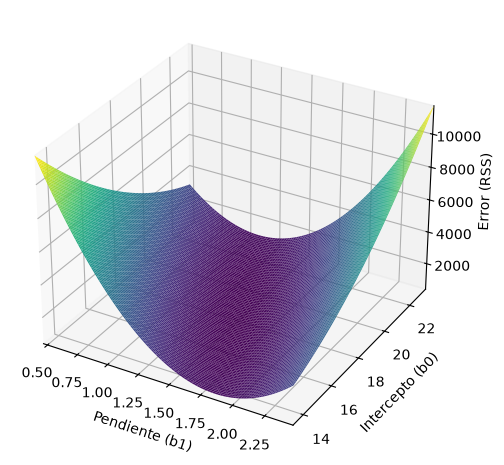

In [35]:
import numpy as np   # vectores
import sympy as sym  # cálculo simbólico
from sympy.plotting import plot3d   # gráficos 3D de sympy

x_d = np.array(experiencia).ravel()   # experiencia como vector
y_d = np.array(salario).ravel()       # salario como vector

b1, b0 = sym.symbols("b1 b0")   # pendiente e intercepto como símbolos

# Suma de errores al cuadrado de todos los datos, escrita directamente con los datos
sum_of_squares = sum((b1 * float(xi) + b0 - float(yi))**2 for xi, yi in zip(x_d, y_d))

# Simplificamos: los términos se agrupan en un polinomio de grado 2 en b1 y b0
sum_of_squares = sym.expand(sum_of_squares)

# Mínimo de mínimos cuadrados, para centrar el gráfico
m_opt, b_opt = np.polyfit(x_d, y_d, 1)

# Graficamos la función (pendiente en b1, intercepto en b0)
_ = plot3d(sum_of_squares,
       (b1, m_opt - 1, m_opt + 1),
       (b0, b_opt - 5, b_opt + 5),
       xlabel="Pendiente (b1)", ylabel="Intercepto (b0)", zlabel="Error (RSS)")

### Descenso de gradiente por lotes

Hasta ahora hemos entrenado y medido el error con todos los datos, pero no podemos olvidar que dividir el conjunto de datos en entrenamiento y prueba es un paso clave para detectar el sobreajuste y medir el rendimiento real del modelo con datos que no ha visto. A partir de aquí entrenaremos solo con la parte de entrenamiento y evaluaremos con la de prueba. Cuando utilizamos todo el conjunto de entrenamiento para hacer los cálculos de descenso de gradiente en cada paso lo llamamos *descenso de gradiente por lotes*. 

Como he comentado antes es importante la tasa de aprendizaje, debemos evaluar diferentes tasas (con una búsqueda exhaustiva por ejemplo). También podríamos limitar el número de iteraciones a un número bajo y eliminar aquellos modelos que tardan demasiado en converger. Si establecemos el número de iteraciones demasiado bajo el algoritmo puede que se detenga muy lejos de la solución óptima, pero si es demasiado alto perderemos tiempo mientras los parámetros del modelo ya no cambian. Una solución sencilla es establecer un número alto de iteraciones pero interrumpir el algoritmo cuando el vector del gradiente se vuelve muy pequeño, es decir, cuando su norma se vuelva más pequeña que un número muy pequeño "E" llamado tolerancia, es que el descenso de gradiente ha llegado (casi) al mínimo.

Cuando la función es convexa y su pendiente no cambia abruptamente, como es el caso de la MSE, el descenso de gradiente por lotes con una tasa de aprendizaje fija (y suficientemente pequeña) acabará convergiendo en la solución óptima (aunque haya que esperar un rato). Si la tasa es demasiado grande, el algoritmo diverge.

In [36]:
# DIVISIÓN EN ENTRENAMIENTO Y PRUEBA
from sklearn.model_selection import train_test_split

# Pasamos los datos a vectores de una dimensión para trabajar más cómodos
x_all = np.array(experiencia).ravel()
y_all = np.array(salario).ravel()

# Nos quedamos con el 80 % de los datos para entrenar y el 20 % para probar.
# Los datos se barajan antes de dividir y con random_state fijamos la semilla,
# así a todos nos sale la misma división
x_train, x_test, y_train, y_test = train_test_split(x_all, y_all, test_size=0.2, random_state=42)
n_tr = len(x_train)
print(f"Entrenamiento: {n_tr} instancias | Prueba: {len(x_test)} instancias")

# Calculamos la solución exacta de mínimos cuadrados, pero solo con los datos de entrenamiento.
# Va a ser nuestra referencia para ver si los demás métodos llegan al mismo sitio
m_ref, b_ref = np.polyfit(x_train, y_train, 1)
print(f"Referencia -> Pendiente: {m_ref:.4f}; Intercepto: {b_ref:.4f}")
print(f"MSE entrenamiento: {mse(y_train, m_ref*x_train + b_ref):.3f} | MSE prueba: {mse(y_test, m_ref*x_test + b_ref):.3f}")

# Aquí vamos guardando la pendiente y el intercepto de cada método para compararlos al final
resultados = {"Exacta (mínimos cuadrados)": (m_ref, b_ref)}

Entrenamiento: 40 instancias | Prueba: 10 instancias
Referencia -> Pendiente: 1.4586; Intercepto: 18.3710
MSE entrenamiento: 7.471 | MSE prueba: 7.167


In [37]:
# DESCENSO DE GRADIENTE POR LOTES

# Creamos un generador aleatorio con semilla, para que a todos nos salgan los mismos números
rng = np.random.default_rng(42)

# Empezamos en un punto aleatorio (dos números sacados de una normal) para la pendiente y el intercepto
pendiente_ini, intercepto_ini = rng.normal(0, 1, size=2)
# Nos guardamos ese punto de partida porque lo vamos a reutilizar en la celda siguiente
pendiente = pendiente_ini
intercepto = intercepto_ini

L = 0.001           # tasa de aprendizaje: el tamaño de los pasos
max_iter = 100000   # número máximo de iteraciones (ponemos uno alto)

for iteracion in range(max_iter):   # repetimos los pasos del descenso de gradiente
    # Residuo de cada instancia de entrenamiento (predicho - real). Usamos todos los datos, eso es el "lote"
    residuos = (pendiente * x_train + intercepto) - y_train

    # Derivada parcial del MSE respecto a la pendiente (media de 2 * x * residuo)
    d_pendiente = (2 * x_train * residuos).sum() / n_tr
    # Derivada parcial del MSE respecto al intercepto (media de 2 * residuo)
    d_intercepto = (2 * residuos).sum() / n_tr


    # Actualizamos la pendiente: nos movemos en sentido contrario a la derivada
    pendiente = pendiente - L * d_pendiente
    # Actualizamos el intercepto de la misma manera
    intercepto = intercepto - L * d_intercepto

print(f"Iteraciones realizadas: {iteracion + 1}")   # cuántas vueltas ha hecho antes de parar
print(f"Pendiente: {pendiente:.4f}; Intercepto: {intercepto:.4f}")   # parámetros que hemos encontrado
print(f"Referencia -> Pendiente: {m_ref:.4f}; Intercepto: {b_ref:.4f}")   # los de la solución exacta, para comparar
print(f"MSE entrenamiento: {mse(y_train, pendiente*x_train + intercepto):.3f} | MSE prueba: {mse(y_test, pendiente*x_test + intercepto):.3f}")   # error con los datos de entrenamiento y con los de prueba

resultados["Lotes"] = (pendiente, intercepto)   # guardamos el resultado para la tabla final

Iteraciones realizadas: 100000
Pendiente: 1.4586; Intercepto: 18.3710
Referencia -> Pendiente: 1.4586; Intercepto: 18.3710
MSE entrenamiento: 7.471 | MSE prueba: 7.167


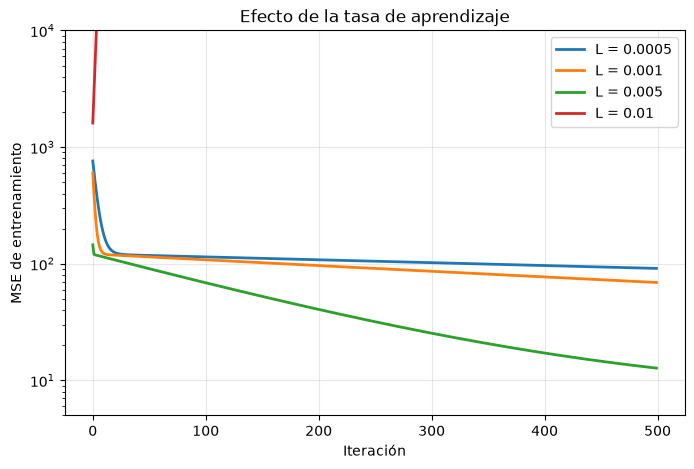

In [38]:
# EFECTO DE LA TASA DE APRENDIZAJE EN EL DESCENSO POR LOTES
# Es el mismo código de antes, pero repetido con varias tasas y partiendo siempre del mismo punto

tasas = [0.0005, 0.001, 0.005, 0.01]   # las tasas de aprendizaje que vamos a comparar

plt.figure(figsize=(8, 5))   # creamos la figura donde dibujaremos las cuatro curvas
for L in tasas:   # probamos cada tasa, una detrás de otra
    pendiente = pendiente_ini       # volvemos al mismo punto de partida de antes
    intercepto = intercepto_ini
    errores = []                    # aquí guardamos el MSE de cada iteración

    
    with np.errstate(all="ignore"): # Con la tasa más grande los números se disparan y numpy avisa, así que silenciamos los avisos
        for iteracion in range(500):   # solo 500 iteraciones para ver cómo arranca cada tasa
            residuos = (pendiente * x_train + intercepto) - y_train    # residuos de todas las instancias
            d_pendiente = (2 * x_train * residuos).sum() / n_tr         # derivada respecto a la pendiente
            d_intercepto = (2 * residuos).sum() / n_tr                  # derivada respecto al intercepto
            pendiente = pendiente - L * d_pendiente                     # actualizamos la pendiente
            intercepto = intercepto - L * d_intercepto                  # actualizamos el intercepto
            errores.append(mse(y_train, pendiente * x_train + intercepto))   # guardamos el error para dibujarlo

    plt.plot(errores, linewidth=2, label=f"L = {L}")   # dibujamos la curva de esta tasa

plt.yscale("log")   # escala logarítmica para que se vean bien errores muy distintos
plt.ylim(5, 1e4)    # limitamos el eje para que no se pierda el detalle de las curvas que bajan
plt.xlabel("Iteración")
plt.ylabel("MSE de entrenamiento")
plt.title("Efecto de la tasa de aprendizaje")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Con las tasas pequeñas el error baja muy despacio. Con L = 0.005 va mucho más rápido hacia el mínimo. Y con L = 0.01 los pasos son tan grandes que nos pasamos del mínimo cada vez más y el error diverge.

## Descenso de gradiente estocástico

Si los conjuntos de entrenamiento son muy grandes, el descenso de gradiente por lotes se hace demasiado lento. Como alternativa surge el **descenso de gradiente estocástico** que elige aleatoriamente una instancia en el conjunto de entrenamiento en cada iteración y calcula los gradientes basándose únicamente en esa instancia. Esto hace que el algoritmo sea mucho más rápido y que permita entrenar conjuntos de datos enormes.

Debido a su naturaleza estocástica, es mucho menos regular que el descenso de gradiente por lotes, es decir, que en vez de descender con suavidad hasta llegar al mínimo, la función rebota arriba y abajo, descendiendo solo como media. Con el tiempo acabará muy cerca del mínimo, pero una vez allí, seguirá rebotando por todas partes sin alcanzarlo nunca. Una vez que el algoritmo se detiene, los valores son buenos pero no óptimos.

A pesar de no alcanzar el mínimo, son varios los beneficios de usar este algoritmo. Permite entrenar grandes conjuntos de datos debido a que reduce la complejidad computacional significativamente. Además, cuando la función de pérdida es muy irregular (no es una función convexa) la aleatoriedad del descenso de gradiente estocástico puede ayudar a que el algoritmo salga de las zonas de mínimos locales, aunque no hay garantía de alcanzar el mínimo global. En nuestro ejemplo la MSE es convexa y no tiene mínimos locales: allí el único efecto de la aleatoriedad es que el algoritmo oscila alrededor del mínimo. 

Por lo tanto, la aleatoriedad es buena para escapar de los óptimos locales, pero mala porque significa que el algoritmo nunca puede asentarse en el mínimo. Una posible solución a este dilema es reducir de manera gradual la tasa de aprendizaje. Inicialmente la tasa puede ser alta para progresar con rapidez y (en funciones no convexas) potencialmente escapar de mínimos locales, y después va haciéndose cada vez más pequeña permitiendo que el algoritmo se asiente cerca del mínimo. La función que determina la tasa de aprendizaje en cada iteración se llama **programación del aprendizaje**. Si la tasa de aprendizaje se reduce demasiado rápido, puede que te atasques en un mínimo local (en funciones no convexas), o incluso te quedes congelado a medio camino hacia el mínimo. Si se reduce demasiado lento, puede que vayas saltando alrededor del mínimo durante mucho tiempo y que acabes en una solución subóptima si detienes el entrenamiento demasiado pronto. En el código siguiente lo comprobamos comparando una tasa constante con una tasa decreciente.

Como las instancias se eligen de manera aleatoria, es posible que algunas instancias se elijan varias veces por repetición, mientras que puede que otras no se elijan nunca. Si queremos asegurarnos que el algoritmo pasa por todas las instancias en cada repetición, otra posibilidad es mezclar el conjunto de entrenamiento (asegurándote de mezclar las variables de entrada y las etiquetas de forma conjunta), pasar por el instancia por instancia, volver a mezclarlo y así sucesivamente.

### Programación de la Tasa de Aprendizaje (Learning Rate Schedule)

#### Decaimiento por tiempo (time-based decay)

$$
L_t = \frac{L_0}{1 + \text{decay} \cdot t}
$$

donde:
- $L_t$ = tasa de aprendizaje en la iteración $t$
- $L_0$ = tasa de aprendizaje inicial
- $\text{decay}$ = factor de decaimiento (controla qué tan rápido baja $L$)
- $t$ = número de iteración actual (en el código, la época)

#### Efecto del decaimiento

- Al inicio ($t=0$): $L_t = L_0$ (paso más grande)
- A medida que $t$ crece: $L_t$ disminuye progresivamente
- Esto permite dar pasos grandes al principio (convergencia rápida) y pasos pequeños al final (evita oscilar cerca del mínimo)

Tasa constante   -> Pendiente: 1.6854; Intercepto: 18.3792 | MSE entrenamiento: 13.507 | MSE prueba: 11.689
Tasa decreciente -> Pendiente: 1.4606; Intercepto: 18.3661 | MSE entrenamiento: 7.471 | MSE prueba: 7.163
Referencia       -> Pendiente: 1.4586; Intercepto: 18.3710


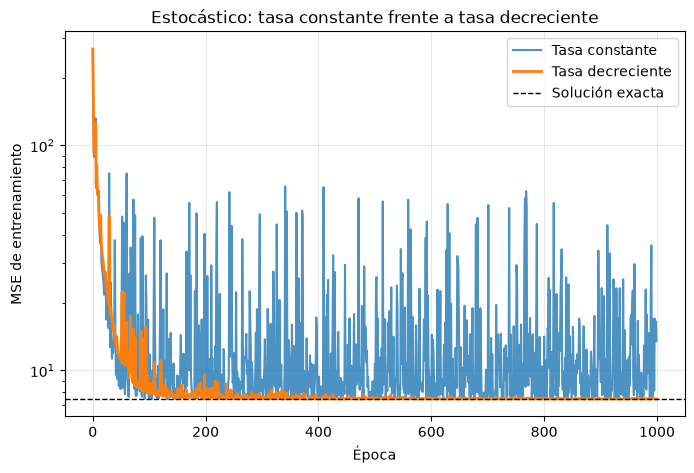

In [39]:
# DESCENSO DE GRADIENTE ESTOCÁSTICO

def descenso_estocastico(L0, decay, epochs):   # L0 = tasa inicial, decay = cuánto decae, epochs = pasadas por los datos
    # Misma semilla en todas las llamadas: mismo punto de partida y mismo orden de los datos
    rng = np.random.default_rng(42)
    pendiente, intercepto = rng.normal(0, 1, size=2)   # punto de partida aleatorio
    errores = []   # aquí guardamos el MSE de entrenamiento al acabar cada época

    for epoch in range(epochs):   # una época = una pasada completa por los datos de entrenamiento
        # Programación del aprendizaje: la tasa va bajando con las épocas (si decay = 0 se queda constante)
        L = L0 / (1 + decay * epoch)

        # Recorremos los datos en un orden aleatorio, distinto en cada época
        for k in rng.permutation(n_tr): # n_tr es len(X_train)
            # Error de UNA sola instancia (predicho - real)
            error = (pendiente * x_train[k] + intercepto) - y_train[k]

            # Actualizamos la pendiente con el gradiente de esa instancia
            pendiente = pendiente - L * 2 * x_train[k] * error
            # Actualizamos el intercepto con el gradiente de esa instancia
            intercepto = intercepto - L * 2 * error

        # Al acabar la época medimos el MSE con todos los datos de entrenamiento
        errores.append(mse(y_train, pendiente * x_train + intercepto))

    return pendiente, intercepto, errores   # devolvemos los parámetros y la curva de error


epochs = 1000   # número de épocas
p_cte, b_cte, err_cte = descenso_estocastico(L0=0.002, decay=0.0, epochs=epochs)    # tasa constante (decay = 0)
p_dec, b_dec, err_dec = descenso_estocastico(L0=0.002, decay=0.02, epochs=epochs)   # tasa decreciente

# Resultados de cada versión, con su error en entrenamiento y en prueba
print(f"Tasa constante   -> Pendiente: {p_cte:.4f}; Intercepto: {b_cte:.4f} | MSE entrenamiento: {mse(y_train, p_cte*x_train + b_cte):.3f} | MSE prueba: {mse(y_test, p_cte*x_test + b_cte):.3f}")
print(f"Tasa decreciente -> Pendiente: {p_dec:.4f}; Intercepto: {b_dec:.4f} | MSE entrenamiento: {mse(y_train, p_dec*x_train + b_dec):.3f} | MSE prueba: {mse(y_test, p_dec*x_test + b_dec):.3f}")
print(f"Referencia       -> Pendiente: {m_ref:.4f}; Intercepto: {b_ref:.4f}")   # solución exacta

resultados["Estocástico (tasa constante)"] = (p_cte, b_cte)      # guardamos para la tabla final
resultados["Estocástico (tasa decreciente)"] = (p_dec, b_dec)

plt.figure(figsize=(8, 5))   # dibujamos cómo baja el error en cada caso
plt.plot(err_cte, linewidth=1.5, alpha=0.8, label="Tasa constante")
plt.plot(err_dec, linewidth=2, label="Tasa decreciente")
# La línea discontinua es el error de la solución exacta, el mejor que se puede conseguir
plt.axhline(mse(y_train, m_ref*x_train + b_ref), color="black", linestyle="--", linewidth=1, label="Solución exacta")
plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("MSE de entrenamiento")
plt.title("Estocástico: tasa constante frente a tasa decreciente")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Importante**: Cuando se utiliza el descenso de gradiente estocástico, las instancias de entrenamiento deben ser independientes e idénticamente distribuidas para garantizar que los parámetros se dirigen al óptimo global, de media. Una manera sencilla de hacerlo es mezclar las instancias durante el entrenamiento (eligiendo cada instancia de forma aleatoria o mezclando el conjunto de entrenamiento al principio de cada repetición). Si no mezclamos las instancias (por ejemplo las instancias están ordenadas por etiqueta), el descenso de gradiente estocástico empezará por optimizar para una etiqueta, luego para la siguiente, y así sucesivamente, y no se asentará cerca del mínimo global.

#### Descenso de gradiente estocástico con scikit-learn (SGDRegressor):

In [40]:
from sklearn.linear_model import SGDRegressor      # regresión lineal entrenada con descenso de gradiente estocástico
from sklearn.preprocessing import StandardScaler   # para escalar las variables

# SGDRegressor funciona mejor con las variables escaladas.
# Primero ponemos x como una columna (n, 1), que es lo que pide scikit-learn
X_train = x_train.reshape(-1, 1)
X_test = x_test.reshape(-1, 1)

# Escalamos: restamos la media y dividimos por la desviación típica.
escalador = StandardScaler()
# El escalador se ajusta SOLO con el entrenamiento (fit_transform), así calcula la media y la desviación con esos datos
X_train_esc = escalador.fit_transform(X_train)
# A prueba le aplicamos la misma transformación (transform), para no colar información del test
X_test_esc = escalador.transform(X_test)

# Probamos los tres tipos de programación del aprendizaje que vimos
for programacion in ["constant", "invscaling", "adaptive"]:
    sgd_reg = SGDRegressor(
        max_iter=5000,             # máximo de épocas (una época = una pasada por todos los datos de entrenamiento)
        tol=1e-5,                  # si la pérdida no mejora más que esto...
        n_iter_no_change=100,      # ...durante 100 épocas seguidas, paramos
        penalty=None,              # sin regularización, igual que en nuestros otros métodos
        eta0=0.01,                 # tasa de aprendizaje inicial
        learning_rate=programacion,  # constant: no cambia; invscaling: baja como eta0/t^0.25; adaptive: se divide entre 5 cuando deja de mejorar
        random_state=42)           # semilla, porque los datos se barajan en cada época
    sgd_reg.fit(X_train_esc, y_train)   # entrenamos con los datos escalados

    # Los parámetros están en la escala de los datos estandarizados, así que los
    # pasamos a las unidades originales (años de experiencia y miles de euros)
    w = sgd_reg.coef_[0]             # pendiente en datos escalados
    c = sgd_reg.intercept_[0]        # intercepto en datos escalados
    media = escalador.mean_[0]       # media de la experiencia en entrenamiento
    desv = escalador.scale_[0]       # desviación típica de la experiencia en entrenamiento
    m_sgd = w / desv                 # pendiente en unidades originales
    b_sgd = c - w * media / desv     # intercepto en unidades originales

    print(f"learning_rate = {programacion}")   # qué programación estamos probando
    print(f"  Épocas realizadas: {sgd_reg.n_iter_}")   # cuántas épocas ha necesitado antes de parar
    print(f"  Pendiente: {m_sgd:.4f}; Intercepto: {b_sgd:.4f} (referencia: {m_ref:.4f} y {b_ref:.4f})")   # parámetros y referencia
    print(f"  MSE entrenamiento: {mse(y_train, sgd_reg.predict(X_train_esc)):.3f} | MSE prueba: {mse(y_test, sgd_reg.predict(X_test_esc)):.3f}")   # errores

    resultados[f"SGDRegressor ({programacion})"] = (m_sgd, b_sgd)   # guardamos para la tabla final

learning_rate = constant
  Épocas realizadas: 175
  Pendiente: 1.4586; Intercepto: 18.3647 (referencia: 1.4586 y 18.3710)
  MSE entrenamiento: 7.471 | MSE prueba: 7.166
learning_rate = invscaling
  Épocas realizadas: 4663
  Pendiente: 1.4586; Intercepto: 18.3708 (referencia: 1.4586 y 18.3710)
  MSE entrenamiento: 7.471 | MSE prueba: 7.167
learning_rate = adaptive
  Épocas realizadas: 819
  Pendiente: 1.4586; Intercepto: 18.3709 (referencia: 1.4586 y 18.3710)
  MSE entrenamiento: 7.471 | MSE prueba: 7.167


### Descenso de gradiente por minilotes

El descenso de gradiente por minilotes calcula los gradientes en conjuntos aleatorios pequeños de instancias llamados minilotes. 

El progreso del algoritmo es menos errático que con el descenso de gradiente estocástico. Como resultado, este algoritmo acabará acercándose un poco más que el descenso de gradiente estocástico pero puede que le resulte más difícil escapar de mínimos locales.

In [41]:
import numpy as np   # librería para trabajar con vectores

# Usamos los datos de entrenamiento
X = x_train
Y = y_train

# Generador aleatorio con semilla y punto de partida aleatorio
rng = np.random.default_rng(42)
pendiente, intercepto = rng.normal(0, 1, size=2)

# Tamaño del minilote: cuántas instancias usamos en cada paso
sample_size = 10
# Tasa de aprendizaje inicial y decaimiento (programación del aprendizaje): L = L0 / (1 + decay * t)
L0 = 0.001
decay = 0.0001
# Número de iteraciones para el descenso de gradiente
iterations = 100000

# Realizamos el descenso de gradiente con minilotes:

for i in range(iterations):   # un paso del descenso por iteración
    # La tasa va bajando poco a poco con las iteraciones
    L = L0 / (1 + decay * i)

    # Elegimos al azar 10 instancias distintas de entrenamiento: ese es el minilote
    idx = rng.choice(n_tr, sample_size, replace=False)
    x_lote = X[idx]   # experiencia del minilote
    y_lote = Y[idx]   # salario del minilote

    # Valor de Y predicho con los parámetros actuales
    y_pred = intercepto + pendiente * x_lote

    # d/dpendiente de la funcion de perdida (calculada solo con el minilote)
    d_pendiente = (-2/sample_size) * np.sum(x_lote * (y_lote - y_pred))

    # d/dintercepto de la funcion de pérdida (calculada solo con el minilote)
    d_intercepto = (-2/sample_size) * np.sum(y_lote - y_pred)

    pendiente = pendiente - L * d_pendiente      # actualizamos la pendiente
    intercepto = intercepto - L * d_intercepto   # actualizamos el intercepto

print(f"Pendiente: {pendiente:.4f}; Intercepto: {intercepto:.4f}")   # parámetros encontrados
print(f"Referencia -> Pendiente: {m_ref:.4f}; Intercepto: {b_ref:.4f}")   # solución exacta
print(f"MSE entrenamiento: {mse(y_train, pendiente*x_train + intercepto):.3f} | MSE prueba: {mse(y_test, pendiente*x_test + intercepto):.3f}")   # errores

resultados["Minilotes"] = (pendiente, intercepto)   # guardamos para la tabla final

Pendiente: 1.4657; Intercepto: 18.3723
Referencia -> Pendiente: 1.4586; Intercepto: 18.3710
MSE entrenamiento: 7.477 | MSE prueba: 7.160


## Comparación de los métodos

Vamos a comparar todo lo que hemos probado. Todos los métodos se han entrenado con los mismos datos de entrenamiento y se evalúan con los de prueba. La referencia es la solución exacta de mínimos cuadrados.

In [42]:
# Tabla resumen con todos los métodos
print(f"{'Método':<34}{'Pendiente':>10}{'Intercepto':>12}{'MSE train':>11}{'MSE test':>10}")
for nombre, (m_, b_) in resultados.items():
    mse_tr = mse(y_train, m_ * x_train + b_)
    mse_te = mse(y_test, m_ * x_test + b_)
    print(f"{nombre:<34}{m_:>10.4f}{b_:>12.4f}{mse_tr:>11.3f}{mse_te:>10.3f}")

Método                             Pendiente  Intercepto  MSE train  MSE test
Exacta (mínimos cuadrados)            1.4586     18.3710      7.471     7.167
Lotes                                 1.4586     18.3710      7.471     7.167
Estocástico (tasa constante)          1.6854     18.3792     13.507    11.689
Estocástico (tasa decreciente)        1.4606     18.3661      7.471     7.163
SGDRegressor (constant)               1.4586     18.3647      7.471     7.166
SGDRegressor (invscaling)             1.4586     18.3708      7.471     7.167
SGDRegressor (adaptive)               1.4586     18.3709      7.471     7.167
Minilotes                             1.4657     18.3723      7.477     7.160
